<a href="https://colab.research.google.com/github/CollisionSeverityPrediction/T12/blob/main/Emma_Sloan_Ass1_T12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline code from T1.1 so this notebook can run standalone


In [ ]:
# importing Python libraries and functions

import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [ ]:
# Loading the dataset into a pandas dataframe
df = pd.read_csv('/content/drive/MyDrive/Assignment_1/dft-road-casualty-statistics-collision-2024.csv')

/tmp/ipykernel_1118/2282544302.py:2: DtypeWarning: Columns (0,2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/Assignment_1/dft-road-casualty-statistics-collision-2024.csv')


In [ ]:
# drop irrelevant columns such as collision, district and road IDs as advised in brief
df.drop(columns=['collision_index', 'collision_year', 'collision_ref_no',
                  'location_easting_osgr', 'location_northing_osgr',
                  'police_force', 'local_authority_district', 'local_authority_ons_district',
                  'local_authority_highway', 'local_authority_highway_current',
                  'first_road_number', 'junction_detail_historic',
                  'pedestrian_crossing_human_control_historic',
                  'pedestrian_crossing_physical_facilities_historic',
                  'carriageway_hazards_historic', 'second_road_number',
                  'did_police_officer_attend_scene_of_accident',
                  'lsoa_of_accident_location'], inplace=True)

In [ ]:
# save target before dropping column
y = df['collision_severity']

In [ ]:
# drop additional columns
df.drop(columns=['longitude', 'latitude', 'collision_severity',
                  'number_of_casualties', 'enhanced_severity_collision',
                  'collision_injury_based', 'collision_adjusted_severity_serious',
                  'collision_adjusted_severity_slight'], inplace=True)

In [ ]:
# drop columns with high percentage of missing/unknown values that introduce data leakage
df.drop(columns=['special_conditions_at_site', 'junction_control', 'second_road_class', 'trunk_road_flag'], inplace=True)

In [ ]:
# feature engineering for date and time. date becomes month and time becomes time_of_day
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
df['time'] = pd.to_datetime(df['time'], format='%H:%M')

# Extract month
df['month'] = df['date'].dt.month

# Extract hour, then bucket it into time-of-day categories
df['hour'] = df['time'].dt.hour

def bucket_hour(hour):
    if 0 <= hour < 6:
        return 'night'
    elif 6 <= hour < 10:
        return 'morning_rush'
    elif 10 <= hour < 16:
        return 'daytime'
    elif 16 <= hour < 19:
        return 'evening_rush'
    else:
        return 'evening'

df['time_of_day'] = df['hour'].apply(bucket_hour)

# Drop the now-redundant raw columns
df.drop(columns=['date', 'time', 'hour'], inplace=True)
X = df

In [ ]:
missing_codes = [-1, 9, 99]
cols_needing_replace = ['junction_detail', 'pedestrian_crossing', 'weather_conditions',
                         'carriageway_hazards', 'road_type', 'road_surface_conditions',
                         'light_conditions', 'speed_limit']
X[cols_needing_replace] = X[cols_needing_replace].replace(missing_codes, np.nan)

In [ ]:
# group features
numeric_features = ['number_of_vehicles']

speed_limit_feature = ['speed_limit']

nominal_mode_impute = ['junction_detail', 'pedestrian_crossing', 'weather_conditions',
                        'carriageway_hazards', 'road_type', 'road_surface_conditions',
                        'light_conditions']

nominal_no_missing = ['month', 'time_of_day', 'first_road_class', 'urban_or_rural_area', 'day_of_week']

In [ ]:
# define transformers for each group of features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

speed_limit_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

nominal_mode_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

nominal_no_impute_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

In [ ]:
# combine all transformers
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('speed_limit', speed_limit_transformer, speed_limit_feature),
    ('nom_mode', nominal_mode_transformer, nominal_mode_impute),
    ('nom_no_impute', nominal_no_impute_transformer, nominal_no_missing),
], remainder='drop')

#

# Set-Up

In [ ]:
# import libraries
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                              precision_recall_fscore_support, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

In [ ]:
# reformulate the collision severity labels
severity_map = {3: 0, 2: 1, 1: 2}
y_3class = y.map(severity_map)

In [ ]:
# set-up k-fold cross validation using stratified k-fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

In [ ]:
# set up a reusable function to gather metrics for fold

def evaluate_fold(y_true, y_pred, labels=[0,1,2]):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'per_class_report': classification_report(y_true, y_pred, labels=labels, output_dict=True),
        'confusion_matrix': confusion_matrix(y_true, y_pred, labels=labels)
    }

In [ ]:
# metrics for all 5 folds
def overall_metrics(fold_results):

  mean_accuracy = np.mean([r['accuracy'] for r in fold_results])
  std_accuracy = np.std([r['accuracy'] for r in fold_results])

  mean_balanced_acc = np.mean([r['balanced_accuracy'] for r in fold_results])
  std_balanced_acc = np.std([r['balanced_accuracy'] for r in fold_results])

  mean_macro_f1 = np.mean([r['macro_f1'] for r in fold_results])
  std_macro_f1 = np.std([r['macro_f1'] for r in fold_results])

  total_confusion_matrix = sum(r['confusion_matrix'] for r in fold_results)

  print(f"Accuracy: {mean_accuracy:.3f} ± {std_accuracy:.3f}")
  print(f"Balanced Accuracy: {mean_balanced_acc:.3f} ± {std_balanced_acc:.3f}")
  print(f"Macro-F1: {mean_macro_f1:.3f} ± {std_macro_f1:.3f}")
  print("Confusion Matrix:")
  print(total_confusion_matrix)

  return {
        'accuracy': (mean_accuracy, std_accuracy),
        'balanced_accuracy': (mean_balanced_acc, std_balanced_acc),
        'macro_f1': (mean_macro_f1, std_macro_f1),
        'confusion_matrix': total_confusion_matrix
    }

In [ ]:
# set up a reusable function to gather per class metrics for each model
def summarize_results(fold_results, class_labels=['Slight', 'Serious', 'Fatal']):
    summary = {}

    for i, label in enumerate(class_labels):
        precision = np.mean([r['per_class_report'][str(i)]['precision'] for r in fold_results])
        recall = np.mean([r['per_class_report'][str(i)]['recall'] for r in fold_results])
        f1 = np.mean([r['per_class_report'][str(i)]['f1-score'] for r in fold_results])
        summary[f'{label}_precision'] = precision
        summary[f'{label}_recall'] = recall
        summary[f'{label}_f1'] = f1
    return summary


# Majority-Class Baseline

In [ ]:
# run the baseline classifier through CV
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

baseline_fold_results = []

for fold_num, (train_idx, val_idx) in enumerate(skf.split(X, y_3class), start=1):

     X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
     y_train, y_val = y_3class.iloc[train_idx], y_3class.iloc[val_idx]

     # create model for this fold

     baseline = DummyClassifier(strategy='most_frequent')

     baseline_model = Pipeline([
         ('preprocessor', preprocessor),
         ('classifier', baseline)
     ])

     baseline_model.fit(X_train, y_train)
     y_pred = baseline_model.predict(X_val)

     # store the metrics for this fold

     baseline_fold_results.append(evaluate_fold(y_val, y_pred))

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

In [ ]:
baseline_overall_metrics = overall_metrics(baseline_fold_results)
baseline_overall_metrics

Accuracy: 0.752 ± 0.000
Balanced Accuracy: 0.333 ± 0.000
Macro-F1: 0.286 ± 0.000
Confusion Matrix:
[[75858     0     0]
 [23567     0     0]
 [ 1502     0     0]]


{'accuracy': (np.float64(0.7516125516962744),
  np.float64(1.820718038768583e-05)),
 'balanced_accuracy': (np.float64(0.3333333333333333), np.float64(0.0)),
 'macro_f1': (np.float64(0.2860649941717467),
  np.float64(3.95612553021682e-06)),
 'confusion_matrix': array([[75858,     0,     0],
        [23567,     0,     0],
        [ 1502,     0,     0]])}

In [ ]:
baseline_summary = summarize_results(baseline_fold_results)
baseline_summary

{'Slight_precision': np.float64(0.7516125516962744),
 'Slight_recall': np.float64(1.0),
 'Slight_f1': np.float64(0.85819498251524),
 'Serious_precision': np.float64(0.0),
 'Serious_recall': np.float64(0.0),
 'Serious_f1': np.float64(0.0),
 'Fatal_precision': np.float64(0.0),
 'Fatal_recall': np.float64(0.0),
 'Fatal_f1': np.float64(0.0)}

# Multi-nomial logistic regression model

In [ ]:
# implement model with class weighting
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_balanced_fold_results = []

for fold_num, (train_idx, val_idx) in enumerate(skf.split(X, y_3class), start=1):

     X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
     y_train, y_val = y_3class.iloc[train_idx], y_3class.iloc[val_idx]

     # create model for this fold

     log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, multi_class='multinomial', solver='lbfgs')

     log_reg_model = Pipeline([
         ('preprocessor', preprocessor),
         ('classifier', log_reg)
     ])

     log_reg_model.fit(X_train, y_train)
     y_pred = log_reg_model.predict(X_val)

     # store the metrics for this fold

     log_balanced_fold_results.append(evaluate_fold(y_val, y_pred))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

In [ ]:
log_balanced_overall_metrics = overall_metrics(log_balanced_fold_results)
log_balanced_overall_metrics

Accuracy: 0.478 ± 0.007
Balanced Accuracy: 0.479 ± 0.007
Macro-F1: 0.329 ± 0.004
Confusion Matrix:
[[40907 16885 18066]
 [ 9557  6439  7571]
 [  283   281   938]]


{'accuracy': (np.float64(0.4784052532404791),
  np.float64(0.007433083334774015)),
 'balanced_accuracy': (np.float64(0.4790011183686434),
  np.float64(0.007464712581066875)),
 'macro_f1': (np.float64(0.3286734903560151),
  np.float64(0.004125944198544583)),
 'confusion_matrix': array([[40907, 16885, 18066],
        [ 9557,  6439,  7571],
        [  283,   281,   938]])}

In [ ]:
log_balanced_summary = summarize_results(log_balanced_fold_results)
log_balanced_summary

{'Slight_precision': np.float64(0.8061000277093029),
 'Slight_recall': np.float64(0.5392576434603861),
 'Slight_f1': np.float64(0.6461653701569204),
 'Serious_precision': np.float64(0.27292497303121777),
 'Serious_recall': np.float64(0.27322079470202254),
 'Serious_f1': np.float64(0.27301394747503177),
 'Fatal_precision': np.float64(0.03531102119273956),
 'Fatal_recall': np.float64(0.6245249169435215),
 'Fatal_f1': np.float64(0.06684115343609312)}

# Random Forest Model

In [ ]:
# final random forest model based on investigations

from sklearn.ensemble import RandomForestClassifier

fold_forest_final_results = []
train_f1_scores_final = []
val_f1_scores_final = []

for fold_num, (train_idx, val_idx) in enumerate(skf.split(X, y_3class), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y_3class.iloc[train_idx], y_3class.iloc[val_idx]

    rf = RandomForestClassifier(random_state=2, n_jobs=-1, n_estimators=200,
                                  max_depth=30, min_samples_leaf=5, class_weight='balanced')
    rf_model = Pipeline([('preprocessor', preprocessor), ('classifier', rf)])
    rf_model.fit(X_train, y_train)

    y_pred = rf_model.predict(X_val)
    y_train_pred = rf_model.predict(X_train)

    train_f1_final = f1_score(y_train, y_train_pred, average='macro')
    val_f1_final = f1_score(y_val, y_pred, average='macro')
    train_f1_scores_final.append(train_f1_final)
    val_f1_scores_final.append(val_f1_final)
    print(f"Fold {fold_num}: train macro-F1 = {train_f1_final:.3f}, val macro-F1 = {val_f1_final:.3f}")

    fold_forest_final_results.append(evaluate_fold(y_val, y_pred))

print(f"\nAverage train macro-F1: {np.mean(train_f1_scores_final):.3f}")
print(f"Average val macro-F1: {np.mean(val_f1_scores_final):.3f}")
print(f"Average gap: {np.mean(train_f1_scores_final) - np.mean(val_f1_scores_final):.3f}")

Fold 1: train macro-F1 = 0.532, val macro-F1 = 0.384
Fold 2: train macro-F1 = 0.531, val macro-F1 = 0.387
Fold 3: train macro-F1 = 0.538, val macro-F1 = 0.388
Fold 4: train macro-F1 = 0.539, val macro-F1 = 0.385
Fold 5: train macro-F1 = 0.542, val macro-F1 = 0.387

Average train macro-F1: 0.536
Average val macro-F1: 0.386
Average gap: 0.150


In [ ]:
forest_final_overall_metrics = overall_metrics(fold_forest_final_results)
forest_final_overall_metrics

Accuracy: 0.600 ± 0.002
Balanced Accuracy: 0.441 ± 0.005
Macro-F1: 0.386 ± 0.001
Confusion Matrix:
[[51287 19971  4600]
 [12318  8849  2400]
 [  404   690   408]]


{'accuracy': (np.float64(0.5998791467246607),
  np.float64(0.0018755572113922385)),
 'balanced_accuracy': (np.float64(0.4410720668360367),
  np.float64(0.004536998026111229)),
 'macro_f1': (np.float64(0.38612792265998847),
  np.float64(0.0014104719779532036)),
 'confusion_matrix': array([[51287, 19971,  4600],
        [12318,  8849,  2400],
        [  404,   690,   408]])}

In [ ]:
forest_final_summary = summarize_results(fold_forest_final_results)
forest_final_summary

{'Slight_precision': np.float64(0.8012537389742451),
 'Slight_recall': np.float64(0.6760922295741544),
 'Slight_f1': np.float64(0.7333652436729647),
 'Serious_precision': np.float64(0.2998901152576326),
 'Serious_recall': np.float64(0.3754827749206669),
 'Serious_f1': np.float64(0.33344159006505725),
 'Fatal_precision': np.float64(0.055074339457674905),
 'Fatal_recall': np.float64(0.27164119601328907),
 'Fatal_f1': np.float64(0.09157693424194355)}

# DNN model

In [ ]:
import numpy as np
import tensorflow as tf
import random
from tensorflow import keras
from tensorflow.keras.optimizers import Adam

SEED = 2
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

Testing Baseline model with cross validation - chosen as final DNN model

In [ ]:
# FINAL DNN MODEL - 5 fold CV for baseline model

tf.random.set_seed(SEED)

baseline_fold_dnn_results = []
baseline_fold_dnn_histories = {}  # store history per fold, needed for learning curve plots

for baseline_fold_num, (baseline_train_idx, baseline_val_idx) in enumerate(skf.split(X, y_3class), start=1):

    tf.random.set_seed(SEED)

    baseline_X_train, baseline_X_val = X.iloc[baseline_train_idx], X.iloc[baseline_val_idx]
    baseline_y_train, baseline_y_val = y_3class.iloc[baseline_train_idx], y_3class.iloc[baseline_val_idx]

    baseline_X_train_transformed = preprocessor.fit_transform(baseline_X_train, baseline_y_train)
    baseline_X_val_transformed = preprocessor.transform(baseline_X_val)

    if hasattr(baseline_X_train_transformed, 'toarray'):
        baseline_X_train_transformed = baseline_X_train_transformed.toarray()
    if hasattr(baseline_X_val_transformed, 'toarray'):
        baseline_X_val_transformed = baseline_X_val_transformed.toarray()

    baseline_n_features = baseline_X_train_transformed.shape[1]

    # class weights, computed on this fold's training labels only
    baseline_weights = compute_class_weight('balanced', classes=np.array([0, 1, 2]), y=baseline_y_train)
    baseline_class_weight_dict = dict(zip([0, 1, 2], baseline_weights))

    # build model
    baseline_model = keras.Sequential([
        keras.Input(shape=(baseline_n_features,)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(3, activation='softmax')
    ])

    baseline_adam = Adam(learning_rate=0.001)
    baseline_model.compile(optimizer=baseline_adam, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    baseline_early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True
    )

    baseline_history = baseline_model.fit(
        baseline_X_train_transformed, baseline_y_train,
        validation_data=(baseline_X_val_transformed, baseline_y_val),
        epochs=100, batch_size=32,
        class_weight=baseline_class_weight_dict,
        callbacks=[baseline_early_stop],
        verbose=0
    )

    baseline_fold_dnn_histories[baseline_fold_num] = baseline_history.history  # for learning curve plots later

    baseline_y_pred_probs = baseline_model.predict(baseline_X_val_transformed, verbose=0)
    baseline_y_pred = np.argmax(baseline_y_pred_probs, axis=1)

    baseline_fold_result = evaluate_fold(baseline_y_val, baseline_y_pred)
    baseline_fold_dnn_results.append(baseline_fold_result)

    print(f"Fold {baseline_fold_num}: macro-F1 = {baseline_fold_result['macro_f1']:.3f} "
          f"(epochs run: {len(baseline_history.history['loss'])})")

print(f"\nAverage macro-F1: {np.mean([r['macro_f1'] for r in baseline_fold_dnn_results]):.3f} "
      f"± {np.std([r['macro_f1'] for r in baseline_fold_dnn_results]):.3f}")

Fold 1: macro-F1 = 0.358 (epochs run: 37)
Fold 2: macro-F1 = 0.355 (epochs run: 30)
Fold 3: macro-F1 = 0.355 (epochs run: 21)
Fold 4: macro-F1 = 0.351 (epochs run: 35)
Fold 5: macro-F1 = 0.358 (epochs run: 37)

Average macro-F1: 0.356 ± 0.003


In [ ]:
baseline_fold_overall_metrics = overall_metrics(baseline_fold_dnn_results)
baseline_fold_overall_metrics

Accuracy: 0.534 ± 0.011
Balanced Accuracy: 0.435 ± 0.027
Macro-F1: 0.356 ± 0.003
Confusion Matrix:
[[44256 22615  8987]
 [10407  9135  4025]
 [  358   642   502]]


{'accuracy': (np.float64(0.5339798290562128),
  np.float64(0.010677357756906702)),
 'balanced_accuracy': (np.float64(0.4351203684933857),
  np.float64(0.027303409285980903)),
 'macro_f1': (np.float64(0.3555603862271235),
  np.float64(0.002531854113332455)),
 'confusion_matrix': array([[44256, 22615,  8987],
        [10407,  9135,  4025],
        [  358,   642,   502]])}

In [ ]:
baseline_fold_summary = summarize_results(baseline_fold_dnn_results)
baseline_fold_summary

{'Slight_precision': np.float64(0.8045377409059018),
 'Slight_recall': np.float64(0.5834058418274572),
 'Slight_f1': np.float64(0.6760455714046532),
 'Serious_precision': np.float64(0.2820499671069401),
 'Serious_recall': np.float64(0.3876186080602304),
 'Serious_f1': np.float64(0.325206382203424),
 'Fatal_precision': np.float64(0.03652445594132387),
 'Fatal_recall': np.float64(0.3343366555924695),
 'Fatal_f1': np.float64(0.06542920507329326)}

# Loss Curves for Final DNN Model

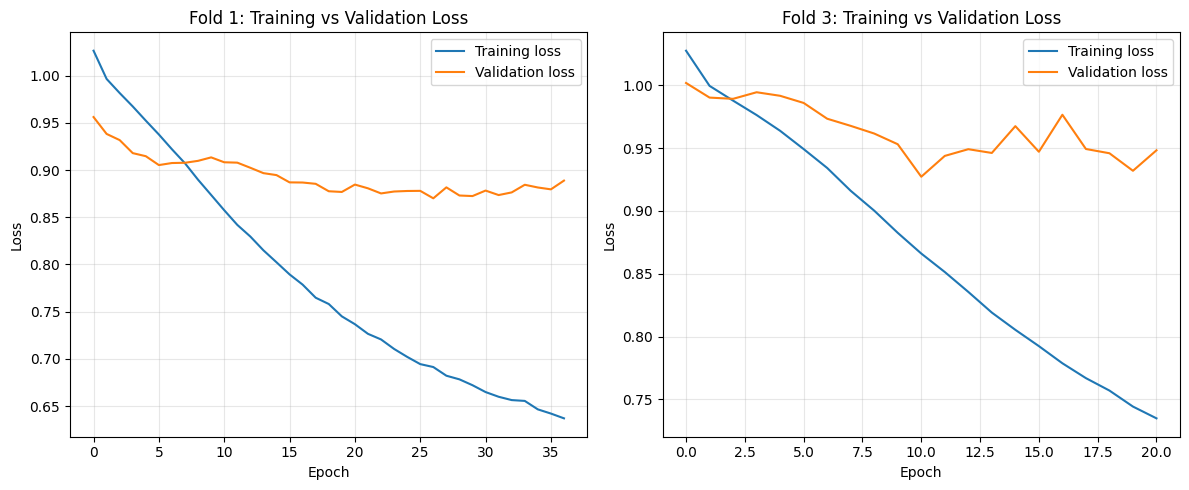

In [ ]:
# Training and validation loss curves for 2 representative folds from the FINAL DNN MODEL

folds_to_plot = [1, 3]

fig, axes = plt.subplots(1, len(folds_to_plot), figsize=(12, 5))

for ax, fold_num in zip(axes, folds_to_plot):
    history = baseline_fold_dnn_histories[fold_num]

    ax.plot(history['loss'], label='Training loss')
    ax.plot(history['val_loss'], label='Validation loss')
    ax.set_title(f'Fold {fold_num}: Training vs Validation Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Summary of results across all models

In [ ]:
import pandas as pd

# Metric comparison - all models

models = {
    'Baseline': {**baseline_overall_metrics, **baseline_summary},
    'Logistic Regression (final)': {**log_balanced_overall_metrics, **log_balanced_summary},
    'Random Forest (final)': {**forest_final_overall_metrics, **forest_final_summary},
    'DNN (final)': {**baseline_fold_overall_metrics, **baseline_fold_summary},
}

metric_columns = [
    'accuracy', 'balanced_accuracy', 'macro_f1',
    'Slight_precision', 'Slight_recall', 'Slight_f1',
    'Serious_precision', 'Serious_recall', 'Serious_f1',
    'Fatal_precision', 'Fatal_recall', 'Fatal_f1',
]

comparison = pd.DataFrame(models).T
comparison = comparison[metric_columns]

# handle the (mean, std) tuples stored for accuracy/balanced_accuracy/macro_f1
for col in ['accuracy', 'balanced_accuracy', 'macro_f1']:
    comparison[col] = comparison[col].apply(lambda x: x[0] if isinstance(x, tuple) else x)

comparison = comparison.round(3)
comparison

,accuracy,balanced_accuracy,macro_f1,Slight_precision,Slight_recall,Slight_f1,Serious_precision,Serious_recall,Serious_f1,Fatal_precision,Fatal_recall,Fatal_f1
Baseline,0.752,0.333,0.286,0.751613,1.0,0.858195,0.0,0.0,0.0,0.0,0.0,0.0
Logistic Regression (final),0.478,0.479,0.329,0.8061,0.539258,0.646165,0.272925,0.273221,0.273014,0.035311,0.624525,0.066841
Random Forest (final),0.600,0.441,0.386,0.801254,0.676092,0.733365,0.29989,0.375483,0.333442,0.055074,0.271641,0.091577
DNN (final),0.534,0.435,0.356,0.804538,0.583406,0.676046,0.28205,0.387619,0.325206,0.036524,0.334337,0.065429


In [ ]:
# Confusion matrix comparison - all models

confusion_matrices = {
    'Baseline': baseline_overall_metrics['confusion_matrix'],
    'Logistic Regression (final)': log_balanced_overall_metrics['confusion_matrix'],
    'Random Forest (final)': forest_final_overall_metrics['confusion_matrix'],
    'DNN (final)': baseline_fold_overall_metrics['confusion_matrix'],
}

class_labels = ['Slight', 'Serious', 'Fatal']

for model_name, cm in confusion_matrices.items():
    print(f"\n{model_name} — Confusion Matrix (summed across 5 folds)")
    cm_df = pd.DataFrame(cm, index=[f'Actual {c}' for c in class_labels],
                              columns=[f'Predicted {c}' for c in class_labels])
    print(cm_df)


Baseline — Confusion Matrix (summed across 5 folds)
                Predicted Slight  Predicted Serious  Predicted Fatal
Actual Slight              75858                  0                0
Actual Serious             23567                  0                0
Actual Fatal                1502                  0                0

Logistic Regression (final) — Confusion Matrix (summed across 5 folds)
                Predicted Slight  Predicted Serious  Predicted Fatal
Actual Slight              40907              16885            18066
Actual Serious              9557               6439             7571
Actual Fatal                 283                281              938

Random Forest (final) — Confusion Matrix (summed across 5 folds)
                Predicted Slight  Predicted Serious  Predicted Fatal
Actual Slight              51287              19971             4600
Actual Serious             12318               8849             2400
Actual Fatal                 404                69